# Physics 129 — Fall 2026

## Homework 7: Boosted decision trees for collider physics

**Due Friday, October 30, 2026 at 11:59 p.m. Pacific Time**

**Grading: This homework is graded for completion only.**

**AI use:** Complete the required AI-use disclosure at the end of the notebook. The disclosure must cover your work on the entire homework.

### How to use this notebook

This homework has two parts:

- **Part 1 is a complete worked example.** Read the explanations and work through the code and outputs to learn the BDT workflow: inspect the inputs, split the sample, construct and train the model, and evaluate its performance.
- **Part 2 is your analysis.** Apply the same workflow in a collider-experiment setting using simulated photon and neutral-pion showers from the ATLAS electromagnetic calorimeter. You will reproduce the shower-shape distributions, train your own BDT, evaluate it, and determine a score threshold that retains 90% of photons.

This entire homework is part of the **final-project rollout**. The photon/pion calorimeter topic is not the final-project topic. The transferable preparation is the method: using a boosted decision tree for event classification, defining an evaluation sample, and choosing a classifier working point.

For Part 2, use a reproducible random half of the available events for training. Reserve the other half as an untouched evaluation sample. Do not train, tune, or select the model using the evaluation half.

# Six-dimensional signal/background separation with a BDT

Generate **20,000 signal + 20,000 background events**, each with six dimensionless features, and train a boosted decision tree using **scikit-learn**. This is a reproducible toy example, not a detector simulation.

Run **Kernel → Restart Kernel and Run All Cells** to repeat the full demonstration. The fixed random seed reproduces the samples and split; execution times depend on DataHub load.

## 1. Imports and settings
The only analysis packages are NumPy, pandas, matplotlib, and scikit-learn, already installed on this DataHub. No GPU is needed.

In [1]:
from time import perf_counter
pipeline_start = perf_counter()
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, accuracy_score, confusion_matrix
from IPython.display import display

SEED = 129
N_PER_CLASS = 20_000
features = [f'x{i}' for i in range(1, 7)]
timings = {}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11})
print(f'Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__}')

Python 3.11.0 | scikit-learn 1.8.0


## 2. Generate two overlapping six-dimensional distributions
Background starts from six independent standard normal variables. Signal has mean shifts in x1–x4 and a modest change in the width of x4. The final pair has **opposite correlations**: x5 and x6 are positively correlated for signal and negatively correlated for background. Their individual distributions are identical, so this pair illustrates information carried by relationships between features.

The correlation magnitude is 0.75. Labels are 1 = signal and 0 = background; labels never enter the feature matrix.

In [2]:
t0 = perf_counter()
rng = np.random.default_rng(SEED)
background = rng.normal(size=(N_PER_CLASS, 6))
signal = rng.normal(size=(N_PER_CLASS, 6))
signal[:, :4] += np.array([0.9, -0.7, 0.6, 0.5])
signal[:, 3] = 0.8 * (signal[:, 3] - 0.5) + 0.5
rho = 0.75
background[:, 5] = -rho * background[:, 4] + np.sqrt(1 - rho**2) * background[:, 5]
signal[:, 5] = rho * signal[:, 4] + np.sqrt(1 - rho**2) * signal[:, 5]
X = np.vstack([background, signal])
y = np.concatenate([np.zeros(N_PER_CLASS, dtype=int), np.ones(N_PER_CLASS, dtype=int)])
assert X.shape == (40_000, 6) and np.isfinite(X).all()
timings['Generate data'] = perf_counter() - t0
print(f'Signal: {signal.shape}; background: {background.shape}')
display(pd.DataFrame({'feature': features, 'signal mean': signal.mean(axis=0),
                      'background mean': background.mean(axis=0),
                      'signal std': signal.std(axis=0), 'background std': background.std(axis=0)}).round(3))

Signal: (20000, 6); background: (20000, 6)


,feature,signal mean,background mean,signal std,background std
0,x1,0.900,-0.011,0.999,1.001
1,x2,-0.702,0.008,1.000,0.992
2,x3,0.595,-0.005,0.998,0.997
3,x4,0.498,-0.000,0.802,1.005
4,x5,-0.005,-0.006,0.997,1.001
5,x6,-0.007,0.002,0.992,1.003


## 3. Inspect the inputs
Each histogram is normalized to unit area. The scatter plots show the class-dependent correlation hidden by the one-dimensional x5 and x6 histograms.

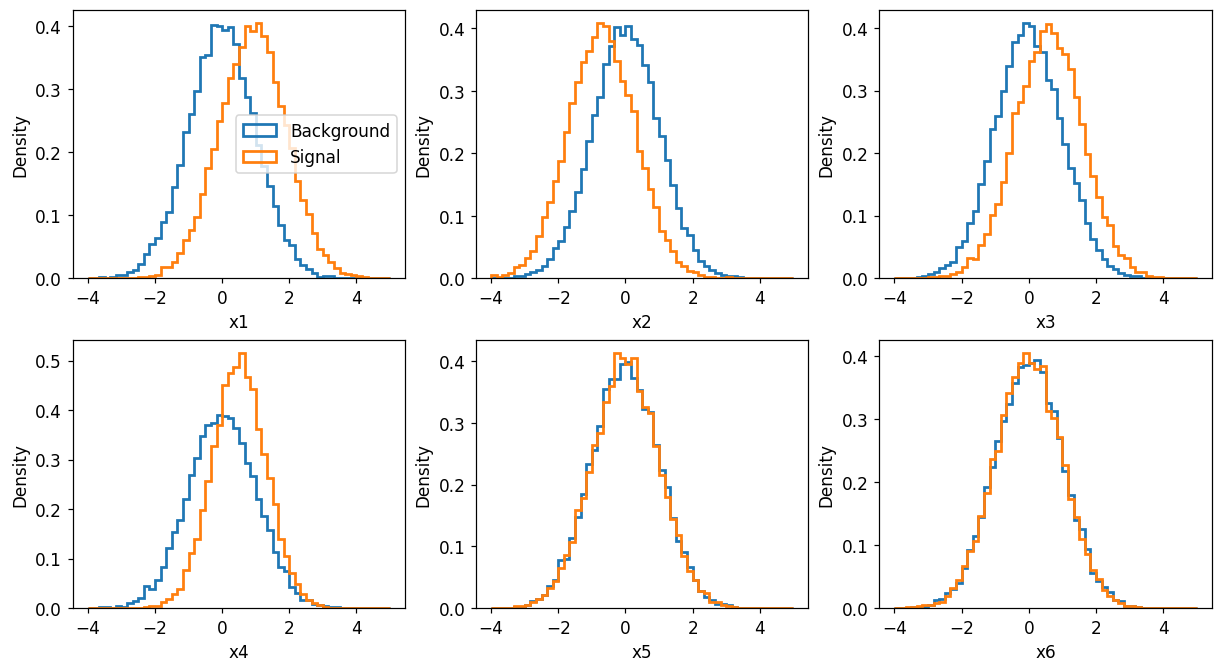

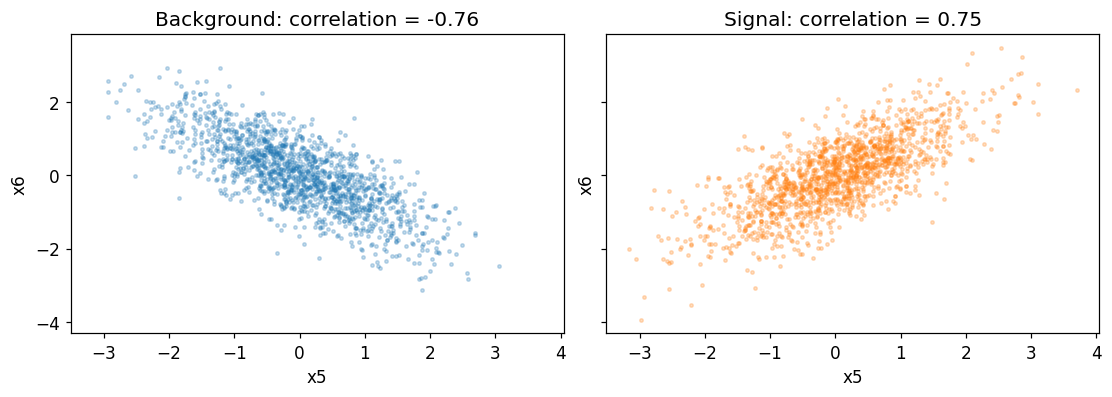

In [3]:
t0 = perf_counter()
fig, axes = plt.subplots(2, 3, figsize=(11, 6), constrained_layout=True)
bins = np.linspace(-4, 5, 55)
for j, ax in enumerate(axes.flat):
    ax.hist(background[:, j], bins=bins, density=True, histtype='step', linewidth=1.8, color='tab:blue', label='Background')
    ax.hist(signal[:, j], bins=bins, density=True, histtype='step', linewidth=1.8, color='tab:orange', label='Signal')
    ax.set(xlabel=features[j], ylabel='Density')
axes[0, 0].legend()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True, sharey=True, constrained_layout=True)
for ax, data, label, color in zip(axes, [background, signal], ['Background', 'Signal'], ['tab:blue', 'tab:orange']):
    ax.scatter(data[:1500, 4], data[:1500, 5], s=5, alpha=0.25, color=color)
    ax.set(xlabel='x5', ylabel='x6', title=f'{label}: correlation = {np.corrcoef(data[:, 4:6].T)[0, 1]:.2f}')
plt.show()
timings['Input plots'] = perf_counter() - t0

## 4. Split before fitting
Use 70% for training (14,000 events per class) and hold out 30% for testing (6,000 per class). Stratification preserves equal class counts. Trees do not require feature standardization. Hyperparameters below are fixed in advance; the test set is used only for evaluation.

In [4]:
t0 = perf_counter()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
timings['Train/test split'] = perf_counter() - t0
print(f'Training: {len(y_train):,} events | test: {len(y_test):,} events')
print('Training counts [background, signal]:', np.bincount(y_train))
print('Test counts [background, signal]:', np.bincount(y_test))

Training: 28,000 events | test: 12,000 events
Training counts [background, signal]: [14000 14000]
Test counts [background, signal]: [6000 6000]


## 5. Train the boosted decision tree
The essential training code is one model constructor and one `.fit(...)` call. We use **200 trees**, maximum depth **3**, learning rate **0.08**, and at least **30 events per leaf**. Boosting adds trees sequentially to improve the current prediction. These settings keep the demonstration modest; no hyperparameter scan is performed.

In [5]:
bdt = GradientBoostingClassifier(
    n_estimators=200, max_depth=3, learning_rate=0.08,
    min_samples_leaf=30, random_state=SEED)
t0 = perf_counter()
bdt.fit(X_train, y_train)
timings['BDT training'] = perf_counter() - t0
print(f'Trained {bdt.n_estimators_} trees in {timings["BDT training"]:.3f} seconds.')

Trained 200 trees in 13.036 seconds.


## 6. Evaluate separation on unseen events
The BDT score increases toward signal. **ROC AUC** is 0.5 for random ranking and 1 for perfect separation. Accuracy uses a fixed score threshold of 0.5. Comparing training and test AUC gives a simple overfitting check. The score is learned for this balanced toy sample; it is not a signal probability for a real experiment with different class rates.

In [6]:
t0 = perf_counter()
test_score = bdt.predict_proba(X_test)[:, 1]
timings['Predict 12,000 test events'] = perf_counter() - t0
t0 = perf_counter()
train_score = bdt.predict_proba(X_train)[:, 1]
timings['Predict 28,000 training events'] = perf_counter() - t0
auc_test = roc_auc_score(y_test, test_score)
auc_train = roc_auc_score(y_train, train_score)
prediction = (test_score >= 0.5).astype(int)
accuracy = accuracy_score(y_test, prediction)
tn, fp, fn, tp = confusion_matrix(y_test, prediction).ravel()
print(f'Train AUC: {auc_train:.4f} | Test AUC: {auc_test:.4f} | Gap: {auc_train-auc_test:.4f}')
print(f'Test accuracy at score >= 0.5: {accuracy:.2%}')
print(f'Signal efficiency: {tp/(tp+fn):.2%} | Background acceptance: {fp/(fp+tn):.2%}')
display(pd.DataFrame([[tn, fp], [fn, tp]], index=['True background', 'True signal'],
                     columns=['Predicted background', 'Predicted signal']))

Train AUC: 0.9452 | Test AUC: 0.9363 | Gap: 0.0089
Test accuracy at score >= 0.5: 85.92%
Signal efficiency: 86.40% | Background acceptance: 14.55%


,Predicted background,Predicted signal
True background,5127,873
True signal,816,5184


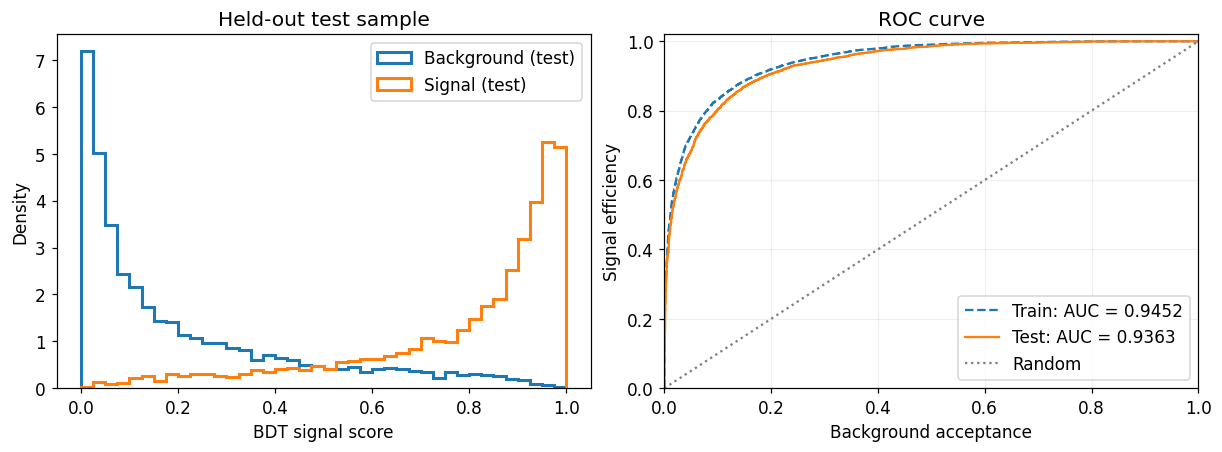

In [7]:
t0 = perf_counter()
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
score_bins = np.linspace(0, 1, 41)
for label, name, color in [(0, 'Background', 'tab:blue'), (1, 'Signal', 'tab:orange')]:
    axes[0].hist(test_score[y_test == label], bins=score_bins, density=True,
                 histtype='step', linewidth=2, label=f'{name} (test)', color=color)
axes[0].set(xlabel='BDT signal score', ylabel='Density', title='Held-out test sample')
axes[0].legend()
for labels, scores, name, style in [(y_train, train_score, 'Train', '--'), (y_test, test_score, 'Test', '-')]:
    fpr, tpr, _ = roc_curve(labels, scores)
    axes[1].plot(fpr, tpr, style, label=f'{name}: AUC = {roc_auc_score(labels, scores):.4f}')
axes[1].plot([0, 1], [0, 1], ':', color='grey', label='Random')
axes[1].set(xlabel='Background acceptance', ylabel='Signal efficiency', title='ROC curve', xlim=(0, 1), ylim=(0, 1.02))
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.show()
timings['Evaluation plots'] = perf_counter() - t0

## 7. Save the pseudo-datasets and report the time
The compressed NumPy file contains the two `(20000, 6)` arrays, feature names, and seed. Timings are wall-clock seconds on this DataHub instance. The full notebook time below includes imports, calculations, rendering, and notebook execution overhead after the first cell starts; it excludes kernel startup and the time spent writing the notebook.

In [8]:
t0 = perf_counter()
np.savez_compressed('pseudo_data_6d.npz', signal=signal, background=background,
                    feature_names=np.array(features), seed=SEED)
timings['Save pseudo-data'] = perf_counter() - t0
pipeline_seconds = perf_counter() - pipeline_start
print(f'BDT TRAINING: {timings["BDT training"]:.3f} s')
print(f'TEST PREDICTION: {timings["Predict 12,000 test events"]:.3f} s')
print(f'FULL NOTEBOOK (excluding kernel startup): {pipeline_seconds:.3f} s')
print(f'TEST AUC: {auc_test:.4f} | TEST ACCURACY: {accuracy:.2%}')
display(pd.DataFrame({'stage': list(timings), 'seconds': list(timings.values())}).round(3))
print('Saved pseudo_data_6d.npz (signal, background, feature_names, seed).')

BDT TRAINING: 13.036 s
TEST PREDICTION: 0.033 s
FULL NOTEBOOK (excluding kernel startup): 30.570 s
TEST AUC: 0.9363 | TEST ACCURACY: 85.92%


,stage,seconds
0,Generate data,0.007
1,Input plots,0.776
2,Train/test split,0.013
3,BDT training,13.036
4,"Predict 12,000 test events",0.033
5,"Predict 28,000 training events",0.076
6,Evaluation plots,0.306
7,Save pseudo-data,0.084


Saved pseudo_data_6d.npz (signal, background, feature_names, seed).


## How complicated is this?
The core workflow is **generate → split → construct model → fit → predict**. Most of this notebook is explanation, visualization, and measurement. Training itself is a single library call.

Try changing `n_estimators` or `max_depth` and rerun to compare time and the train/test AUC gap. If you start selecting settings based on performance, introduce a separate validation split or cross-validation and keep a final test sample untouched. For real physics analysis, realistic simulation, event weights, systematic uncertainties, leakage control, and validating background modeling require more work than this toy training.

To load the saved data later: `data = np.load("pseudo_data_6d.npz")`, then `signal = data["signal"]` and `background = data["background"]`.

---

# Part 2: Photon--pion separation with calorimeter shower shapes

Part 1 above demonstrated the complete workflow

**inspect inputs $\rightarrow$ split the sample $\rightarrow$ construct a model $\rightarrow$ fit $\rightarrow$ predict $\rightarrow$ evaluate**.

You will now apply the same workflow to simulated data from the ATLAS electromagnetic calorimeter. The goal is to distinguish photons ($\gamma$) from neutral pions ($\pi^0$) and determine a BDT score cut that retains 90% of photons.

The sample contains events with $25 < E_{\mathrm{true}} < 35\ \mathrm{GeV}$, $|\eta|<1.25$, and calorimeter noise enabled. It contains 1,851 photons and 1,879 neutral pions.

Use only the seven shower-shape variables listed below as BDT inputs. Do not use `particle`, `event`, `e_true_gev`, or `eta` as classifier inputs.

## 2.1 Read and inspect the CSV file

Each row in `shower_shapes_30gev.csv` is one simulated event. The columns are:

| Column | Meaning |
|---|---|
| `particle` | `gamma` or `pi0` |
| `event` | event identifier |
| `e_true_gev` | true energy in GeV |
| `eta` | pseudorapidity |
| `r_eta`, `r_phi`, `w_eta2`, `f1`, `f3`, `e_ratio`, `f_side` | seven calorimeter shower-shape variables |

1. Read the CSV file with pandas.
2. Display the first few rows and the column names.
3. Verify that the sample has 3,730 rows, no missing values, 1,851 `gamma` events, and 1,879 `pi0` events.
4. Verify that all events satisfy the stated energy and pseudorapidity selections.

In [ ]:
SHOWER_DATA_FILE = "shower_shapes_30gev.csv"

SHOWER_FEATURES = [
    "r_eta", "r_phi", "w_eta2", "f1", "f3", "e_ratio", "f_side"
]

# TODO: Read the CSV file into a DataFrame named shower_df.
# TODO: Display the requested checks.

**Briefly describe what each row represents and state whether your checks agree with the sample description.**

Your answer:

## 2.2 Reproduce the shower-shape plots

If you correctly read the seven **shower-shape variables** from the CSV file, you should be able to produce normalized photon and neutral-pion distributions like the reference figure below. Small differences in binning or plotting style are acceptable, but the overall shapes, relative shifts, tails, and median values should agree.

### Provided reference plot

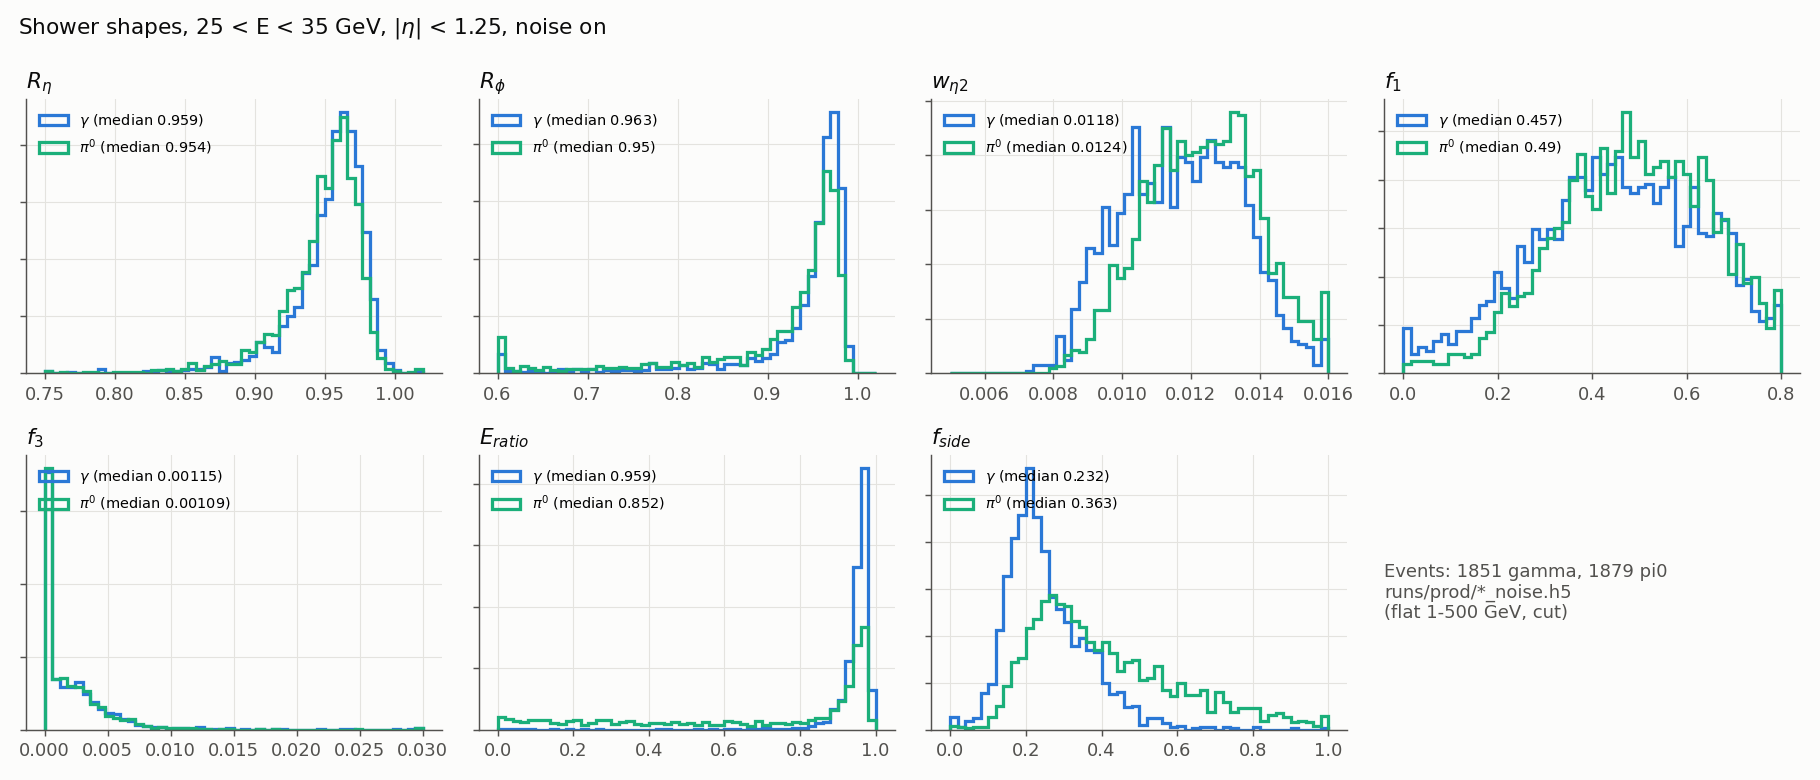

For each of the seven shower-shape variables:

1. Overlay the photon and neutral-pion distributions.
2. Use step histograms normalized to unit area (`density=True`).
3. Use the same bin edges for the two particle types.
4. Label each curve with its particle type and median.
5. Label the horizontal axis with the corresponding physics symbol.

Arrange the plots in a $2\times4$ grid and turn off the unused eighth panel. The plotting ranges below match the reference image. Values outside a displayed range remain in the CSV and must not be removed from the BDT input.

In [ ]:
SHOWER_FEATURE_LABELS = {
    "r_eta": r"$R_\eta$",
    "r_phi": r"$R_\phi$",
    "w_eta2": r"$w_{\eta 2}$",
    "f1": r"$f_1$",
    "f3": r"$f_3$",
    "e_ratio": r"$E_{\mathrm{ratio}}$",
    "f_side": r"$f_{\mathrm{side}}$",
}

SHOWER_PLOT_RANGES = {
    "r_eta": (0.75, 1.02),
    "r_phi": (0.60, 1.02),
    "w_eta2": (0.005, 0.016),
    "f1": (0.00, 0.80),
    "f3": (0.00, 0.030),
    "e_ratio": (0.00, 1.00),
    "f_side": (0.00, 1.00),
}

# TODO: Make the 2 x 4 grid of normalized step histograms.
# Suggested colors: tab:blue for gamma and #12B878 for pi0.

**Which variables show the clearest separation between photons and neutral pions? Which show substantial overlap? Support your answer using features visible in your plots, such as shifts, widths, tails, or medians.**

Your answer:

## 2.3 Use a random half of the events for training

Define the target as

$$
y = \begin{cases}
1 & \text{for } \gamma,\\
0 & \text{for } \pi^0.
\end{cases}
$$

Use `train_test_split` to put a random half of the events into the training sample and the other half into an untouched evaluation sample. Use `test_size=0.50`, `stratify=y_shower`, and `random_state=SEED` so that the split is reproducible and both halves retain the photon/pion proportions.

Print the total size and class counts of both samples. Do not fit, tune, or select the model using the evaluation half.

In [ ]:
# TODO: Build X_shower from the seven columns in SHOWER_FEATURES.
# TODO: Encode gamma as 1 and pi0 as 0 in y_shower.
# TODO: Make the stratified random 50/50 split described above.
# TODO: Print the sample sizes and class counts.

## 2.4 Train the BDT

Follow the Part 1 example. Use the training half to fit a `GradientBoostingClassifier` with the same fixed settings:

```python
GradientBoostingClassifier(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.08,
    min_samples_leaf=30,
    random_state=SEED,
)
```

These settings are supplied so that everyone solves the same classification problem. Do not perform a hyperparameter scan.

In [ ]:
# TODO: Construct a model named shower_bdt with the specified settings.
# TODO: Fit it using only the training half.

## 2.5 Evaluate the classifier

1. Use `predict_proba(... )[:, 1]` to calculate the photon score for the training and evaluation events.
2. Report the ROC AUC for both samples.
3. Plot the evaluation-sample BDT score distributions for photons and pions using normalized step histograms.
4. Plot the evaluation-sample ROC curve with pion acceptance on the horizontal axis and photon efficiency on the vertical axis.
5. Comment on the difference between the training and evaluation AUC values.

In [ ]:
# TODO: Calculate training and evaluation BDT scores and ROC AUC values.
# TODO: Make the score-distribution and ROC plots.

## 2.6 Find the cut for 90% photon efficiency

For a BDT score threshold $c$, define the photon efficiency on the evaluation sample as

$$
\epsilon_\gamma(c) =
\frac{N_\gamma(\mathrm{score}\geq c)}{N_\gamma}.
$$

Determine the **highest** threshold $c$ for which the finite evaluation sample gives $\epsilon_\gamma(c)\geq0.90$. Apply that same threshold to the evaluation pions and calculate

$$
\epsilon_{\pi^0}(c) =
\frac{N_{\pi^0}(\mathrm{score}\geq c)}{N_{\pi^0}},
$$

the pion acceptance. Also report the pion rejection, $1-\epsilon_{\pi^0}$.

Add the selected threshold to your BDT score plot as a vertical line. Report the threshold with enough digits for another student to reproduce your achieved efficiency.

In [ ]:
# TODO: Determine the finite-sample threshold using only evaluation photon scores.
# TODO: Report the cut, achieved photon efficiency, pion acceptance, and pion rejection.
# TODO: Add the cut to the BDT score plot.

### Interpretation

In a short paragraph, explain:

- what the BDT score represents,
- why the cut must be derived from events that were not used to train the classifier,
- what is gained and lost by choosing a working point with 90% photon efficiency, and
- whether the training/evaluation comparison suggests overfitting.

Your answer:

## Required AI-use disclosure

Artificial intelligence tools may be used to support your learning and to prepare this homework submission. Regardless of whether you use AI, you are fully responsible for everything you submit and must be able to explain your work without AI assistance when asked by the instructor.

Include one disclosure covering your work on the **entire homework**:

- If you **did not use AI**, state: “I did not use AI technology to complete this homework.”
- If you **used AI**, identify every platform or software tool used and include the exact prompts you entered. You may also briefly describe how you used the output.

The content of your disclosure will not affect the completion grade, but the disclosure and all required details must be present. A submission without an AI-use disclosure, or one that acknowledges AI use but omits the platform/software or prompts, will be returned without being graded.

Your disclosure: